# Survival impact of adipose genes in Schildkraut HGSOC

## Overview
To validate the deconvolution-derived adipocyte survival association independently of the deconvolution method, we constructed an adipocyte metagene score directly from bulk RNA-seq expression data. Canonical adipocyte marker genes were selected from PanglaoDB (Franzén et al., 2019), retaining genes with a ubiquitousness index ≤ 0.01 (detected in at most 1–2 of 178 reference cell types), yielding 52 candidate genes of which 22 were detectable in the preprocessed bulk RNA-seq data. The metagene score was computed as the mean log1p-normalized expression across these 22 genes, z-scored across all samples, and tested for association with overall survival using the same stage-stratified Cox proportional hazards framework as the primary analysis.

## Results
Both models were significant and consistent in direction with the deconvolution-based findings:
- **Main model** (n=566, adjusted for age, BMI, race): HR = 1.12, 95% CI 1.02–1.24, p = 0.023
- **Restricted model** (n=262, additionally adjusted for residual disease): HR = 1.25, 95% CI 1.06–1.47, p = 0.007

## Conclusion
Higher adipocyte transcriptional signal in bulk tumor RNA-seq is independently associated with worse overall survival in HGSOC, supporting the robustness of the adipocyte–survival association beyond deconvolution-derived estimates.

In [36]:
import pandas as pd
import numpy as np
from lifelines import CoxPHFitter
import numpy as np, pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
from scipy.stats import zscore
from matplotlib.ticker import FixedLocator, FuncFormatter, LogLocator, NullFormatter
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(1, "../../")
sys.path.insert(1, "../")

import src.hp as hp
import src.params as params

pd.set_option("display.max_rows", 100)
plt.style.use("default")

np.random.seed(90)

In [37]:
cell_types_to_use = ["Adipocytes"]  # Adipocytes, Stromal, Immune, Epithelial
complete_case = True
use_interview_time = True

In [38]:
map_stage = True
remove_unknown_stage = True
remove_999_BMI = True
kaplan_meier = True

## Paths

In [39]:
base_path = os.path.dirname(os.getcwd())
meta_path = os.path.join(base_path, "input_data/metadata.xlsx")

from pathlib import Path
output_data = Path(base_path) / "output_data"

### Formatting for below plots, etc.

In [40]:
if complete_case:
    remove_treatment = False
    remove_pts_with_unknowns = True

else:
    remove_treatment = True
    remove_pts_with_unknowns = False

In [41]:
## The order for the plots below
desired_order = [
    "Age",
    "BMI",
    "Race: Black",
    "Residual: < 1cm",
    "Residual: ≥ 1cm",
]
if remove_treatment:
    desired_order.remove("Residual: < 1cm")
    desired_order.remove("Residual: ≥ 1cm")
desired_order

['Age', 'BMI', 'Race: Black', 'Residual: < 1cm', 'Residual: ≥ 1cm']

In [42]:
# continuous covariates to keep “as is”
cont_cols = ["Age", "BMI"]

## Load InstaPrism cell-fraction tables (processed) and metadata

Proportions

In [43]:
props = pd.read_csv(
    os.path.join(base_path, "input_data/proportions_sch.csv"), index_col=0
)
props

,SampleID,Plasma cells,B cells,Endothelial cells,T cells,Monocytes,Fibroblasts,NK cells,Epithelial cells,DC,pDC,ILC,Macrophages,Mast cells,Erythroid,Adipocytes,Dataset,suid,ID
0,18341X10,4.919765e-49,0.052767,0.029870,1.833554e-26,1.727071e-60,7.074672e-105,8.375315e-10,0.746341,1.257780e-139,3.590420e-30,2.867046e-78,1.185148e-02,1.538137e-57,0.0,0.159171,SchildkrautB,18341X10,45369
1,18341X12,9.351753e-92,0.027159,0.011666,5.972580e-66,2.258210e-157,8.180384e-107,8.135649e-61,0.848153,3.276474e-210,2.054386e-103,1.247009e-85,2.337775e-128,1.452291e-115,0.0,0.113022,SchildkrautB,18341X12,47261
2,18341X13,6.998799e-32,0.014663,0.041547,1.004614e-23,3.232466e-34,1.225464e-02,9.550579e-19,0.819028,1.104356e-115,3.157063e-69,7.123720e-41,2.994756e-02,1.850941e-63,0.0,0.082561,SchildkrautB,18341X13,47791
3,18341X14,2.410384e-97,0.162711,0.022343,2.056824e-52,5.485488e-33,2.751866e-120,7.904174e-39,0.642545,4.774011e-154,1.326676e-75,2.334007e-77,1.516542e-02,1.488048e-80,0.0,0.157235,SchildkrautB,18341X14,47916
4,18341X15,3.439318e-76,0.050581,0.055021,5.687981e-28,5.314872e-52,8.961526e-02,2.919113e-22,0.649017,7.625379e-122,1.873123e-52,3.487465e-81,1.419715e-02,4.216693e-41,0.0,0.141568,SchildkrautB,18341X15,48002
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
583,20160X95,1.442627e-108,0.136578,0.014420,3.410104e-30,3.267116e-82,7.666630e-23,1.501224e-35,0.710289,6.509988e-151,4.903142e-78,8.571710e-105,3.473745e-03,5.671299e-79,0.0,0.135240,SchildkrautW,20160X95,47786
584,20160X96,1.359916e-92,0.190881,0.017396,5.383974e-33,2.734703e-86,1.156925e-02,1.945285e-24,0.592805,1.063562e-147,5.374615e-82,8.551669e-96,1.270617e-02,4.370517e-04,0.0,0.174205,SchildkrautW,20160X96,47903
585,20160X97,7.862780e-79,0.102850,0.053137,8.610293e-03,1.076987e-46,4.237821e-02,1.467756e-05,0.656171,3.397744e-114,5.089409e-39,1.625064e-79,2.253584e-02,9.865474e-05,0.0,0.114204,SchildkrautW,20160X97,47926
586,20160X98,1.245316e-60,0.127050,0.034344,1.345753e-16,5.846372e-04,2.787547e-02,2.169830e-04,0.673204,4.422809e-95,4.998254e-48,3.881728e-35,5.796692e-04,4.236351e-47,0.0,0.136146,SchildkrautW,20160X98,47937


In [44]:
# --- Adipocyte metagene score (replaces proportions when cell_types_to_use == ["Adipocytes"]) ---

# load bulk expression 
expr_list = []
for ds in ["SchildkrautB", "SchildkrautW"]:
    path = output_data / "bulk_datasets" / f"{ds}_filtered_asImported.csv"
    df = pd.read_csv(path, index_col=0)  # rows=samples, cols=genes
    expr_list.append(df)
expr_sch = pd.concat(expr_list, axis=0)

# verify the index matches SampleID before mapping
overlap = props["SampleID"].isin(expr_sch.index).sum()
print(f"Samples matched between props and expr: {overlap} / {len(props)}")
if overlap == 0:
    raise ValueError("No samples matched — check that expr_sch.index contains SampleID values")

# select canonical adipocyte markers from PanglaoDB
# ubiquitousness <= 0.01 = detected in at most 1-2 of 178 reference cell types
panglaodb_path = os.path.join(base_path, "input_data/PanglaoDB_markers_27_Mar_2020.tsv")
panglaodb = pd.read_csv(panglaodb_path, sep="\t")
total_cell_types = panglaodb["cell type"].nunique()

adipo_all = panglaodb[
    (panglaodb["cell type"] == "Adipocytes") &
    (panglaodb["canonical marker"] == 1) &
    (panglaodb["ubiquitousness index"] <= 0.01) &
    (panglaodb["species"].str.contains("Hs"))
]
adipo_markers_panglaodb = adipo_all["official gene symbol"].tolist()
print(f"PanglaoDB canonical adipocyte markers (ubiquity<=0.01, <=1-2 of {total_cell_types} cell types): {len(adipo_markers_panglaodb)} genes")

# keep only those detectable in expression data
adipo_markers = [g for g in adipo_markers_panglaodb if g in expr_sch.columns]
print(f"Detected in bulk RNA-seq: {len(adipo_markers)} genes")
print("Markers used:", adipo_markers)

# metagene score = mean log1p expression across markers, z-scored across samples
expr_log = np.log1p(expr_sch[adipo_markers])
metagene_score = expr_log.mean(axis=1)  # index = SampleID
metagene_score = pd.Series(zscore(metagene_score), index=expr_sch.index)  # preserve index for mapping

props["Adipocytes"] = props["SampleID"].map(metagene_score)
print("Metagene score added to props. NaNs:", props["Adipocytes"].isna().sum())

props

Samples matched between props and expr: 588 / 588
PanglaoDB canonical adipocyte markers (ubiquity<=0.01, <=1-2 of 178 cell types): 52 genes
Detected in bulk RNA-seq: 22 genes
Markers used: ['P2RX5', 'UCP1', 'PRDM16', 'FFAR2', 'ADRB1', 'ADRB3', 'TBX1', 'ADIPOQ', 'SLC2A4', 'PLIN1', 'PCK1', 'PPARG', 'STAT6', 'ZBTB16', 'GULP1', 'FZD4', 'FGF7', 'GDF10', 'CCL11', 'AZGP1', 'PPARGC1A', 'ZNF423']
Metagene score added to props. NaNs: 0


,SampleID,Plasma cells,B cells,Endothelial cells,T cells,Monocytes,Fibroblasts,NK cells,Epithelial cells,DC,pDC,ILC,Macrophages,Mast cells,Erythroid,Adipocytes,Dataset,suid,ID
0,18341X10,4.919765e-49,0.052767,0.029870,1.833554e-26,1.727071e-60,7.074672e-105,8.375315e-10,0.746341,1.257780e-139,3.590420e-30,2.867046e-78,1.185148e-02,1.538137e-57,0.0,1.158102,SchildkrautB,18341X10,45369
1,18341X12,9.351753e-92,0.027159,0.011666,5.972580e-66,2.258210e-157,8.180384e-107,8.135649e-61,0.848153,3.276474e-210,2.054386e-103,1.247009e-85,2.337775e-128,1.452291e-115,0.0,-0.676813,SchildkrautB,18341X12,47261
2,18341X13,6.998799e-32,0.014663,0.041547,1.004614e-23,3.232466e-34,1.225464e-02,9.550579e-19,0.819028,1.104356e-115,3.157063e-69,7.123720e-41,2.994756e-02,1.850941e-63,0.0,0.192483,SchildkrautB,18341X13,47791
3,18341X14,2.410384e-97,0.162711,0.022343,2.056824e-52,5.485488e-33,2.751866e-120,7.904174e-39,0.642545,4.774011e-154,1.326676e-75,2.334007e-77,1.516542e-02,1.488048e-80,0.0,-0.111117,SchildkrautB,18341X14,47916
4,18341X15,3.439318e-76,0.050581,0.055021,5.687981e-28,5.314872e-52,8.961526e-02,2.919113e-22,0.649017,7.625379e-122,1.873123e-52,3.487465e-81,1.419715e-02,4.216693e-41,0.0,1.108438,SchildkrautB,18341X15,48002
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
583,20160X95,1.442627e-108,0.136578,0.014420,3.410104e-30,3.267116e-82,7.666630e-23,1.501224e-35,0.710289,6.509988e-151,4.903142e-78,8.571710e-105,3.473745e-03,5.671299e-79,0.0,-0.742225,SchildkrautW,20160X95,47786
584,20160X96,1.359916e-92,0.190881,0.017396,5.383974e-33,2.734703e-86,1.156925e-02,1.945285e-24,0.592805,1.063562e-147,5.374615e-82,8.551669e-96,1.270617e-02,4.370517e-04,0.0,-1.761951,SchildkrautW,20160X96,47903
585,20160X97,7.862780e-79,0.102850,0.053137,8.610293e-03,1.076987e-46,4.237821e-02,1.467756e-05,0.656171,3.397744e-114,5.089409e-39,1.625064e-79,2.253584e-02,9.865474e-05,0.0,-0.242854,SchildkrautW,20160X97,47926
586,20160X98,1.245316e-60,0.127050,0.034344,1.345753e-16,5.846372e-04,2.787547e-02,2.169830e-04,0.673204,4.422809e-95,4.998254e-48,3.881728e-35,5.796692e-04,4.236351e-47,0.0,0.104559,SchildkrautW,20160X98,47937


In [45]:
# Keep only the columns of interest
keep_cols = cell_types_to_use + ["SampleID", "Dataset", "ID"]
props = props[keep_cols]

## Merge, encode categorical covariates

### Build the analysis table  (clinical + cell fractions)


In [46]:
renaming = hp.get_variable_renaming()
renaming.pop("tissue", None)

'Tissue'

Metadata

In [47]:
## Importing and renaming metadata

# ------------------------------ clinical columns -----------------
meta_full = (
    pd.read_excel(meta_path, sheet_name=0)
    .rename(columns=str.strip)
    .rename(columns=renaming)
)

meta_full = meta_full[renaming.values()]

meta_full["Stage"] = pd.to_numeric(meta_full["Stage"], errors="coerce")

meta_full["Event"] = meta_full["Event"].astype(int)
meta_full["Time-Years"] = meta_full["Time_Yrs"]
meta_full.pop("Time_Yrs")
meta_full["Time-Days"] = meta_full["Time-Years"] * 365.22

# Removing patients that received adj. therapy in the complete case model
if complete_case:
    print("filtering samples that did not receive AdjTx")
    print("Original n =", meta_full.shape[0])
    to_rm_adjtx = meta_full[meta_full["AdjTx"] == 2]["ID"].unique().tolist()
    meta_full = meta_full[~meta_full["ID"].isin(to_rm_adjtx)]
    props = props[~props["ID"].isin(to_rm_adjtx)]
    print("New n =", meta_full.shape[0])


meta_full

filtering samples that did not receive AdjTx
Original n = 588
New n = 581


,ID,Age,Event,Stage,Race,Debulk,Hispanic,BMI,NeoTx,AdjTx,Residual,Time-Years,Time-Days
0,40143,63,1,3,1,2.0,2,23.218229,2.0,1.0,4.0,8.739220,3191.737824
1,41377,54,1,3,1,2.0,2,17.428942,2.0,NaN,3.0,1.180014,430.964599
2,41387,55,1,3,2,1.0,2,45.470350,2.0,1.0,2.0,11.983573,4376.640495
3,41391,60,1,3,1,2.0,2,31.340800,2.0,NaN,3.0,4.993840,1823.850185
4,41435,59,1,3,1,NaN,2,23.922658,NaN,NaN,NaN,4.057495,1481.878275
...,...,...,...,...,...,...,...,...,...,...,...,...,...
583,310266,40,0,3,2,NaN,2,28.349557,NaN,NaN,NaN,9.702186,3543.432295
584,320012,66,0,3,2,2.0,2,37.677475,2.0,1.0,4.0,11.767760,4297.821147
585,320025,60,1,3,2,2.0,2,38.740537,2.0,1.0,3.0,6.827869,2493.674262
586,320043,57,1,3,2,2.0,2,19.854802,2.0,1.0,4.0,1.553425,567.341754


In [48]:
meta_full

,ID,Age,Event,Stage,Race,Debulk,Hispanic,BMI,NeoTx,AdjTx,Residual,Time-Years,Time-Days
0,40143,63,1,3,1,2.0,2,23.218229,2.0,1.0,4.0,8.739220,3191.737824
1,41377,54,1,3,1,2.0,2,17.428942,2.0,NaN,3.0,1.180014,430.964599
2,41387,55,1,3,2,1.0,2,45.470350,2.0,1.0,2.0,11.983573,4376.640495
3,41391,60,1,3,1,2.0,2,31.340800,2.0,NaN,3.0,4.993840,1823.850185
4,41435,59,1,3,1,NaN,2,23.922658,NaN,NaN,NaN,4.057495,1481.878275
...,...,...,...,...,...,...,...,...,...,...,...,...,...
583,310266,40,0,3,2,NaN,2,28.349557,NaN,NaN,NaN,9.702186,3543.432295
584,320012,66,0,3,2,2.0,2,37.677475,2.0,1.0,4.0,11.767760,4297.821147
585,320025,60,1,3,2,2.0,2,38.740537,2.0,1.0,3.0,6.827869,2493.674262
586,320043,57,1,3,2,2.0,2,19.854802,2.0,1.0,4.0,1.553425,567.341754


In [49]:
if use_interview_time:
    # ------------------------------ clinical columns -----------------
    meta_new_path = os.path.join(base_path, "input_data/AACES_clinical.csv")
    meta_new = pd.read_csv(meta_new_path)
    meta_new["ID"] = meta_new.suid
    meta_new.index = meta_new.ID

    intersect = np.intersect1d(meta_full["ID"].unique(), meta_new.index.unique())
    meta_new = meta_new.loc[intersect]
    old_idx = meta_full.index
    meta_full.index = meta_full.ID

    meta_full["Time-Days"] = meta_new["days_int_to_event"]
    meta_full["Time-Years"] = meta_new["days_int_to_event"] / 365.22
    meta_full["Event"] = meta_new["vital_status_fin"].astype(float)

    meta_full.index = old_idx

Filtering samples

In [50]:
# Mapping unknown residual treatment size to >=1cm
meta_full["Residual"] = meta_full["Residual"].replace(
    4.0, 3.0
)  ## Making the residual disaease unknow size

if remove_unknown_stage:
    first = meta_full.shape[0]
    meta_full = meta_full[meta_full["Stage"] != 9]
    print("Removed for unknown stage: ", first - meta_full.shape[0])

if remove_999_BMI:
    first = meta_full.shape[0]
    meta_full = meta_full[meta_full["BMI"] != 999]
    print("Removed for BMI 999: ", first - meta_full.shape[0])

# In no case we'd use Hispanic variable:
meta_full.drop(columns=["Hispanic"], inplace=True)

# We are removing debulking treatment that includes CA125.
meta_full.drop(columns=["Debulk"], inplace=True)
meta_full.drop(columns=["NeoTx"], inplace=True)
meta_full.shape

Removed for unknown stage:  9
Removed for BMI 999:  13


(559, 10)

In [51]:
summary_black = hp.meta_summary_table(meta_full[meta_full.Race == 2])
summary_black

,Clinical Variable,Category/Statistic,Value
0,Race,Race = 2,256.00
1,Age at Diagnosis,N,256.00
2,Age at Diagnosis,Mean,57.92
3,Age at Diagnosis,Std,9.80
4,Age at Diagnosis,Min,35.00
5,Age at Diagnosis,Max,78.00
6,Vital Status,Deceased,192.00
7,Vital Status,Alive/Censored,64.00
8,Years from diagnosis to last follow up,N,256.00
9,Years from diagnosis to last follow up,Mean,5.38


In [52]:
summary_white = hp.meta_summary_table(meta_full[meta_full.Race == 1])
summary_white

,Clinical Variable,Category/Statistic,Value
0,Race,Race = 1,303.00
1,Age at Diagnosis,N,303.00
2,Age at Diagnosis,Mean,58.45
3,Age at Diagnosis,Std,9.36
4,Age at Diagnosis,Min,31.00
5,Age at Diagnosis,Max,74.00
6,Vital Status,Deceased,258.00
7,Vital Status,Alive/Censored,45.00
8,Years from diagnosis to last follow up,N,303.00
9,Years from diagnosis to last follow up,Mean,6.04


In [53]:
# If we remove treatment we only keep Race and Stage of the categoricals.
if remove_treatment:
    cat_cols = ["Stage", "Race"]
else:
    # Match Notebook 1: Stage, Race, Residual, AdjTx as categoricals
    cat_cols = ["Stage", "Race", "Residual", "AdjTx"]

meta_full[cat_cols] = meta_full[cat_cols].astype("category")
meta_full.columns

Index(['ID', 'Age', 'Event', 'Stage', 'Race', 'BMI', 'AdjTx', 'Residual',
       'Time-Years', 'Time-Days'],
      dtype='object')

In [54]:
# ------------------------------ merge meta + props ----------------------------
# every SampleID maps to a unique suid)
analysis = props.merge(meta_full, on="ID", how="inner")

print(f"Using: {analysis.shape[0]} rows, {analysis['ID'].nunique()} patients")

analysis

Using: 559 rows, 559 patients


,Adipocytes,SampleID,Dataset,ID,Age,Event,Stage,Race,BMI,AdjTx,Residual,Time-Years,Time-Days
0,1.158102,18341X10,SchildkrautB,45369,53,1.0,3,2,31.110562,1.0,3.0,1.256777,459.0
1,-0.676813,18341X12,SchildkrautB,47261,57,1.0,3,2,29.448927,NaN,NaN,4.531515,1655.0
2,0.192483,18341X13,SchildkrautB,47791,45,1.0,3,2,40.981420,NaN,NaN,4.224851,1543.0
3,-0.111117,18341X14,SchildkrautB,47916,68,1.0,4,2,28.928061,NaN,NaN,1.766059,645.0
4,1.108438,18341X15,SchildkrautB,48002,44,1.0,3,2,24.991295,1.0,2.0,1.130825,413.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
554,-0.742225,20160X95,SchildkrautW,47786,68,1.0,3,1,31.538819,NaN,NaN,1.785225,652.0
555,-1.761951,20160X96,SchildkrautW,47903,45,1.0,3,1,20.410354,NaN,NaN,2.540934,928.0
556,-0.242854,20160X97,SchildkrautW,47926,52,0.0,3,1,34.458370,NaN,NaN,14.112042,5154.0
557,0.104559,20160X98,SchildkrautW,47937,43,1.0,3,1,20.156950,1.0,2.0,2.724385,995.0


In [55]:
if map_stage:
    stage_map = {1: 1, 2: 1, 3: 2, 4: 2}
    analysis["Stage"] = analysis.Stage.map(stage_map)

if remove_pts_with_unknowns:
    print("Going from: ", analysis.shape)
    # require known Residual AND known AdjTx
    analysis = analysis.dropna(subset=["Residual", "AdjTx"])
    print("To: ", analysis.shape)

Going from:  (559, 13)
To:  (262, 13)


In [56]:
if complete_case:
    print("Saving complete case IDs")
    analysis["ID"].to_csv(
        f"{os.getcwd()}/../results/IDs_complete_case.csv", index=False
    )
elif complete_case == False:
    print("Saving reduced  IDs")
    analysis["ID"].to_csv(f"{os.getcwd()}/../results/IDs_reduced_cov.csv", index=False)

Saving complete case IDs


In [57]:
if remove_treatment:
    cols = [
        "Age",
        "Event",
        "Time-Years",
        "BMI",
        "Time-Days",
        "Stage",
        "Residual",
    ]

    cat_cols = ["Race"]
else:
    cols = ["Age", "Event", "Time-Years", "BMI", "Time-Days", "Stage"]

    # Match Notebook 1: include Residual, AdjTx, Race
    cat_cols = ["Residual", "Race"]

# Get dummys for categorical columns with more than 2 cats (NaN counts as category)
dummies = pd.get_dummies(analysis, columns=cat_cols, drop_first=True, prefix_sep="_")

dummies.drop(columns=cols, inplace=True)  # remove original covariates
dummies.drop(columns=props.columns, inplace=True)  # remove original proportions
dummies.drop(columns=["AdjTx"], inplace=True)
dummies

,Residual_2.0,Residual_3.0,Race_2
0,False,True,True
4,True,False,True
9,True,False,True
17,True,False,True
18,True,False,True
...,...,...,...
549,False,True,False
550,True,False,False
551,True,False,False
557,True,False,False


In [58]:
for col in dummies:
    print(dummies[col].value_counts(dropna=False))

Residual_2.0
False    172
True      90
Name: count, dtype: int64
Residual_3.0
False    187
True      75
Name: count, dtype: int64
Race_2
True     151
False    111
Name: count, dtype: int64


In [59]:
# Put together the analysis DataFrame
# (keep the original categorical columns for later use)
analysis_enc = pd.concat([analysis, dummies], axis=1)  # Columns that go into the model
cell_cols = props.columns.difference(["SampleID", "Dataset", "ID"])  # fractions
covars = cont_cols + list(dummies.columns) + list(cell_cols) + ["Stage"]

covars

['Age', 'BMI', 'Residual_2.0', 'Residual_3.0', 'Race_2', 'Adipocytes', 'Stage']

In [60]:
cox_df = analysis_enc[["Time-Days", "Event"] + covars].copy()

if "Race_2" in cox_df.columns:
    cox_df.rename(columns={"Race_2": "Race: Black"}, inplace=True)
if "Residual_3.0" in cox_df.columns:
    cox_df.rename(columns={"Residual_3.0": "Residual: ≥ 1cm"}, inplace=True)
    cox_df.rename(columns={"Residual_2.0": "Residual: < 1cm"}, inplace=True)

In [61]:
print("Design matrix:", cox_df.shape)
print("Design matrix columns:", cox_df.columns)
cox_df

Design matrix: (262, 9)
Design matrix columns: Index(['Time-Days', 'Event', 'Age', 'BMI', 'Residual: < 1cm',
       'Residual: ≥ 1cm', 'Race: Black', 'Adipocytes', 'Stage'],
      dtype='object')


,Time-Days,Event,Age,BMI,Residual: < 1cm,Residual: ≥ 1cm,Race: Black,Adipocytes,Stage
0,459.0,1.0,53,31.110562,False,True,True,1.158102,2
4,413.0,1.0,44,24.991295,True,False,True,1.108438,2
9,1601.0,1.0,67,32.198190,True,False,True,0.648180,2
17,287.0,1.0,71,23.620798,True,False,True,-1.651771,2
18,810.0,1.0,51,21.873770,True,False,True,0.418744,2
...,...,...,...,...,...,...,...,...,...
549,579.0,1.0,47,39.153028,False,True,False,-0.098886,2
550,4080.0,1.0,57,43.240248,True,False,False,1.064846,2
551,1880.0,1.0,71,20.892489,True,False,False,0.044104,2
557,995.0,1.0,43,20.156950,True,False,False,0.104559,2


In [62]:
# ------------------------------ fit penalised CoxPH ------------------------------
cph = CoxPHFitter()

cph.fit(
    cox_df,
    show_progress=True,
    strata="Stage",
    duration_col="Time-Days",
    event_col="Event",
)

cph.print_summary(columns=["coef", "exp(coef)", "p", "z"])

cph.check_assumptions(cox_df)

Iteration 1: norm_delta = 5.09e-01, step_size = 0.9500, log_lik = -925.45018, newton_decrement = 1.66e+01, seconds_since_start = 0.0
Iteration 2: norm_delta = 3.63e-02, step_size = 0.9500, log_lik = -909.95187, newton_decrement = 1.88e-01, seconds_since_start = 0.0
Iteration 3: norm_delta = 1.62e-03, step_size = 0.9500, log_lik = -909.76512, newton_decrement = 3.98e-04, seconds_since_start = 0.0
Iteration 4: norm_delta = 1.75e-06, step_size = 1.0000, log_lik = -909.76472, newton_decrement = 1.47e-10, seconds_since_start = 0.0
Convergence success after 4 iterations.


<lifelines.CoxPHFitter: fitted with 262 total observations, 61 right-censored observations>
             duration col = 'Time-Days'
                event col = 'Event'
                   strata = Stage
      baseline estimation = breslow
   number of observations = 262
number of events observed = 201
   partial log-likelihood = -909.76
         time fit was run = 2026-04-28 17:32:19 UTC

---
                 coef exp(coef)    z      p
covariate                                  
Age              0.01      1.01 0.90   0.37
BMI              0.00      1.00 0.48   0.63
Residual: < 1cm  0.41      1.51 2.27   0.02
Residual: ≥ 1cm  0.85      2.34 4.54 <0.005
Race: Black      0.04      1.04 0.25   0.81
Adipocytes       0.23      1.25 2.71   0.01
---
Concordance = 0.62
Partial AIC = 1831.53
log-likelihood ratio test = 31.37 on 6 df
-log2(p) of ll-ratio test = 15.50

Proportional hazard assumption looks okay.


[]

In [63]:
if complete_case:
    title_for_plot = f"Restricted Model (n={cox_df.shape[0]})"
else:
    title_for_plot = f"Main Model (n={cox_df.shape[0]})"

In [64]:
summary_small = (
    cph.summary[["exp(coef)", "p"]]
    .rename(columns={"exp(coef)": "HazardRatio", "p": "P-Value"})
    .reset_index()  # moves the index into a column
    .rename(columns={"covariate": "Covariate"})  # give that column a nicer name
)
summary_small["Model"] = title_for_plot

new_order = ["Model"] + [c for c in summary_small.columns if c != "Model"]
summary_small = summary_small[new_order]
# take a look
display(summary_small.style.hide(axis="index"))
summary_small.to_clipboard(index=False, excel=True)

Model,Covariate,HazardRatio,P-Value
Restricted Model (n=262),Age,1.006887,0.368856
Restricted Model (n=262),BMI,1.004774,0.631344
Restricted Model (n=262),Residual: < 1cm,1.514078,0.023032
Restricted Model (n=262),Residual: ≥ 1cm,2.335096,0.000006
Restricted Model (n=262),Race: Black,1.040769,0.806126
Restricted Model (n=262),Adipocytes,1.252812,0.006761


In [65]:
# Full table
cph.summary

,coef,exp(coef),se(coef),coef lower 95%,coef upper 95%,exp(coef) lower 95%,exp(coef) upper 95%,cmp to,z,p,-log2(p)
covariate,,,,,,,,,,,
Age,0.006863,1.006887,0.007637,-0.008106,0.021832,0.991927,1.022072,0.0,0.898619,0.368856,1.438872
BMI,0.004763,1.004774,0.009926,-0.014692,0.024217,0.985416,1.024513,0.0,0.479836,0.631344,0.663501
Residual: < 1cm,0.414807,1.514078,0.182500,0.057112,0.772501,1.058775,2.165174,0.0,2.272909,0.023032,5.440236
Residual: ≥ 1cm,0.848053,2.335096,0.186875,0.481784,1.214322,1.618960,3.368011,0.0,4.538065,0.000006,17.426369
Race: Black,0.039960,1.040769,0.162819,-0.279159,0.359080,0.756419,1.432011,0.0,0.245427,0.806126,0.310923
Adipocytes,0.225390,1.252812,0.083219,0.062284,0.388497,1.064264,1.474762,0.0,2.708396,0.006761,7.208563


In [66]:
# Full table
dataframe_to_save = cph.summary.copy()
title = "Main Model" if not complete_case else "Restricted Model"
dataframe_to_save["model"] = title
save_path = f"{os.getcwd()}/../results/coxph_summary_adipogenes_{cell_types_to_use[0]}_{title.replace(' ','_')}.csv"
dataframe_to_save.to_csv(save_path)

In [67]:
# Full table
dataframe_to_save = cph.summary.copy()
title = "Main Model" if not complete_case else "Restricted Model"
dataframe_to_save["model"] = title
save_path = f"{os.getcwd()}/../results/coxph_summary_adipogenes_{title.replace(' ','_')}.csv"
dataframe_to_save.to_csv(save_path)

title_to_open = "Main Model" if complete_case else "Restricted Model"
save_path = f"{os.getcwd()}/../results/coxph_summary_adipogenes_{title_to_open.replace(' ','_')}.csv"
other_model = pd.read_csv(save_path, index_col=0)
results = pd.concat([other_model, dataframe_to_save])
results

,coef,exp(coef),se(coef),coef lower 95%,coef upper 95%,exp(coef) lower 95%,exp(coef) upper 95%,cmp to,z,p,-log2(p),model
covariate,,,,,,,,,,,,
Age,0.011752,1.011821,0.005074,0.001806,0.021698,1.001808,1.021935,0.0,2.315935,0.020562,5.603887,Main Model
BMI,0.007505,1.007534,0.006572,-0.005376,0.020387,0.994638,1.020596,0.0,1.141933,0.253482,1.980047,Main Model
Race: Black,0.000337,1.000337,0.102449,-0.200460,0.201134,0.818354,1.222788,0.0,0.003286,0.997378,0.003787,Main Model
Adipocytes,0.117504,1.124686,0.051795,0.015987,0.219021,1.016116,1.244857,0.0,2.268627,0.023291,5.424081,Main Model
Age,0.006863,1.006887,0.007637,-0.008106,0.021832,0.991927,1.022072,0.0,0.898619,0.368856,1.438872,Restricted Model
BMI,0.004763,1.004774,0.009926,-0.014692,0.024217,0.985416,1.024513,0.0,0.479836,0.631344,0.663501,Restricted Model
Residual: < 1cm,0.414807,1.514078,0.182500,0.057112,0.772501,1.058775,2.165174,0.0,2.272909,0.023032,5.440236,Restricted Model
Residual: ≥ 1cm,0.848053,2.335096,0.186875,0.481784,1.214322,1.618960,3.368011,0.0,4.538065,0.000006,17.426369,Restricted Model
Race: Black,0.039960,1.040769,0.162819,-0.279159,0.359080,0.756419,1.432011,0.0,0.245427,0.806126,0.310923,Restricted Model


In [68]:
summ_cop = cph.summary.copy()
summ = results.loc[cell_types_to_use[0]]
col = summ["model"]
summ.index = col.values
summ = summ.sort_index()
summ

,coef,exp(coef),se(coef),coef lower 95%,coef upper 95%,exp(coef) lower 95%,exp(coef) upper 95%,cmp to,z,p,-log2(p),model
Main Model,0.117504,1.124686,0.051795,0.015987,0.219021,1.016116,1.244857,0.0,2.268627,0.023291,5.424081,Main Model
Restricted Model,0.225390,1.252812,0.083219,0.062284,0.388497,1.064264,1.474762,0.0,2.708396,0.006761,7.208563,Restricted Model


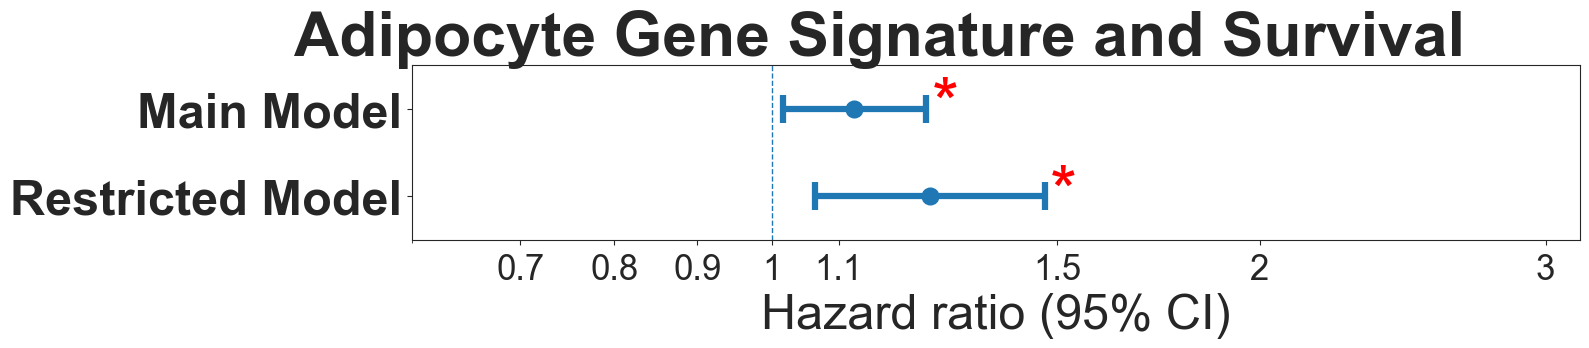

In [69]:
# ------------------------------------------------------------------
# Pull the numbers we need on the log(HR)
# ------------------------------------------------------------------
sns.set_style("ticks", {"xtick.major.size": 5, "ytick.major.size": 5})

# Locate the 95% CI columns, version-agnostic
ci_lower_col = [c for c in summ.columns if c.startswith("coef lower")][0]
ci_upper_col = [c for c in summ.columns if c.startswith("coef upper")][0]

# Work directly on the log scale (β = log(HR))
summ["HR"] = np.exp(summ["coef"])
summ["lower95"] = np.exp(summ[ci_lower_col])
summ["upper95"] = np.exp(summ[ci_upper_col])

# Plot on a linear x-axis whose units are log(HR)
fig, ax = plt.subplots(figsize=(16, 1.8 * len(summ)))
ypos = np.arange(len(summ))

ax.errorbar(
    x=summ["HR"],
    y=ypos,
    xerr=[summ["HR"] - summ["lower95"], summ["upper95"] - summ["HR"]],
    fmt="o",
    capsize=10,
    linewidth=4.5,
    elinewidth=4.5,
    capthick=4.5,
    markersize=12,
)

# Stars for p-values
for i, p in enumerate(summ["p"]):
    if p < 0.05:
        ax.text(
            summ["upper95"].iloc[i] + 0.01,
            ypos[i],
            "*",
            va="center",
            fontsize=50,
            color="red",
        )
    if p < 0.005:
        ax.text(
            summ["upper95"].iloc[i] + 0.01,
            ypos[i],
            "**",
            va="center",
            fontsize=50,
            color="red",
        )
    if p < 0.0005:
        ax.text(
            summ["upper95"].iloc[i] + 0.01,
            ypos[i],
            "***",
            va="center",
            fontsize=50,
            color="red",
        )
padding = 0.5
ax.set_ylim(-padding, len(summ) - 1 + padding)
ax.set_xscale("log")
ax.set_yticks(ypos)
ax.tick_params(axis="x", labelsize=25)
ax.set_yticklabels(summ.index, fontsize=35, fontweight="bold")
ax.set_ylabel("", fontsize=35)
ax.set_xlabel("Hazard ratio (95% CI)", fontsize=35)
ax.set_title(
    f"Adipocyte Gene Signature and Survival", fontsize=45, fontweight="bold", y=1.01, x=0.4
)

# 1) Fixed limits for all figures
ax.set_xscale("log")
ax.set_xlim(0.6, 3.15)

# 2) Fixed major tick *values* (same everywhere)
fixed_ticks = [0.7, 0.8, 0.9, 1.0, 1.1, 1.5, 2.0, 3.0]
ax.xaxis.set_major_locator(FixedLocator(fixed_ticks))


# 3) Plain decimal labels (no 10^x, no 1e-01), tidy zeros
def plain_fmt(x, pos):
    if x < 1:
        s = f"{x:.2f}"
    elif x < 10:
        s = f"{x:.1f}"
    else:
        s = f"{x:g}"
    return s.rstrip("0").rstrip(".")


ax.xaxis.set_major_formatter(FuncFormatter(plain_fmt))

# 4)  minor tick marks only (no labels)
ax.xaxis.set_minor_locator(LogLocator(base=10, subs=(2, 3, 4, 5, 6, 7, 8, 9)))
ax.xaxis.set_minor_formatter(NullFormatter())

# 5) Styling (adjust size if they feel tight)
ax.tick_params(axis="x", which="major", labelsize=22, pad=6)

# 4) styling
ax.tick_params(axis="x", which="major", labelsize=25)
ax.axvline(1, ls="--", lw=1)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

In [70]:
# confirm metagene score is what's in props["Adipocytes"] as check
print("Min:", props["Adipocytes"].min())
print("Max:", props["Adipocytes"].max())
print("Mean:", props["Adipocytes"].mean())

Min: -6.04601565523439
Max: 3.9927947134152113
Mean: 0.00447312139146164


* **HR > 1** → Higher covariate value is associated with **shorter** survival.  
* **HR < 1** → Higher covariate value is associated with **longer** survival.